# Phần 2: Phân Tích So Sánh Dữ Liệu Lịch Sử (2024 - 2025) Với Dữ Liệu Kiểm Thử (2026)
## Cơ Sở Khoa Học Xác Lập Xu Hướng Tăng Trưởng (YoY Trend), Dịch Chuyển Lịch Tết & Độ Trôi Dạt Dữ Liệu

---

### 1. Vì Sao Bắt Buộc Phải Phân Tích & So Sánh 2024, 2025 Với 2026?
Một câu hỏi mang tính chiến lược trong bài toán dự báo chuỗi thời gian: *"Có cần phải phân tích những dữ liệu cũ của năm 2024 và 2025 để so sánh với năm 2026 không?"*
Câu trả lời là: **CỰC KỲ CẦN THIẾT và là bước BẮT BUỘC**, vì 5 nguyên nhân cốt lõi:
1. **Quy luật cùng kỳ Quý 1 (Q1 YoY Seasonality):** Tập test cần dự báo là **Quý 1/2026**. Hành vi mua sắm cafe trong Quý 1 chịu ảnh hưởng của các sự kiện lớn lặp lại hàng năm: Sau Tết Dương Lịch 01/01, Lễ Tình Nhân Valentine 14/02, Quốc tế Phụ Nữ 08/03.
2. **Sự dịch chuyển của Tết Âm Lịch (Lunar New Year Drift):**
   - Tết 2024: Mùng 1 là **10/02/2024**.
   - Tết 2025: Mùng 1 là **29/01/2025** *(Tết rất sớm)*.
   - Tết 2026: Mùng 1 là **17/02/2026** *(Tết muộn)*.
   Nếu không phân tích so sánh để đồng bộ theo trục `tet_offset`, mô hình sẽ bị sai lệch nghiêm trọng.
3. **Đo lường xu hướng tăng trưởng dài hạn (Global Trend):** Phân tích 2024 và 2025 giúp tính toán tốc độ tăng trưởng doanh thu tự nhiên của chuỗi cà phê.
4. **So sánh chính sách khuyến mãi & độ bứt phá doanh thu:** Đối chiếu 380 ngày promo năm 2026 với 3.034 ngày promo của 2024–2025.
5. **Đánh giá độ trôi dạt thời tiết (Weather Drift):** Nhiệt độ mùa đông Hà Nội và mùa khô TP.HCM.

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

for p in [os.path.abspath(".."), os.path.abspath("."), os.path.abspath("../..")]:
    if os.path.exists(os.path.join(p, "data")):
        DATA_DIR = os.path.join(p, "data")
    if p not in sys.path and os.path.exists(os.path.join(p, "src")):
        sys.path.insert(0, p)

from src.cleaning import clean_train, clean_stores, clean_weather, clean_holidays, clean_test

# 1. Đọc và làm sạch toàn bộ dữ liệu
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
stores_raw = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
weather_raw = pd.read_csv(os.path.join(DATA_DIR, "weather.csv"))
holidays_raw = pd.read_csv(os.path.join(DATA_DIR, "holidays.csv"))

stores_c = clean_stores(stores_raw)
weather_c = clean_weather(weather_raw, stores_c["city"].unique())
nat_hol, evt_hol, tet_dates = clean_holidays(holidays_raw)
train_c, _ = clean_train(train_raw, stores_c)
test_c, _ = clean_test(test_raw, stores_c)

# Tách năm
train_c["year"] = train_c["date"].dt.year
test_c["year"] = test_c["date"].dt.year

print("TỔNG QUAN DỮ LIỆU QUA 3 NĂM:")
print(f"- Năm 2024 (Train) : {len(train_c[train_c['year'] == 2024]):,} dòng")
print(f"- Năm 2025 (Train) : {len(train_c[train_c['year'] == 2025]):,} dòng")
print(f"- Năm 2026 (Test)  : {len(test_c):,} dòng")

TỔNG QUAN DỮ LIỆU QUA 3 NĂM:
- Năm 2024 (Train) : 12,281 dòng
- Năm 2025 (Train) : 14,219 dòng
- Năm 2026 (Test)  : 3,869 dòng


### 2. So Sánh Cùng Kỳ Quý 1: Q1/2024 vs Q1/2025 vs Q1/2026 (YoY Analysis)

In [2]:
# Lọc riêng Quý 1 của 3 năm
q1_2024 = train_c[(train_c["date"] >= "2024-01-01") & (train_c["date"] <= "2024-03-31")].copy()
q1_2025 = train_c[(train_c["date"] >= "2025-01-01") & (train_c["date"] <= "2025-03-31")].copy()
q1_2026 = test_c.copy()

yoy_table = pd.DataFrame([
    {
        "Chỉ Số So Sánh": "Khoảng thời gian",
        "Q1/2024 (Lịch sử)": "01/01 - 31/03/2024",
        "Q1/2025 (Lịch sử)": "01/01 - 31/03/2025",
        "Q1/2026 (Tập Test)": "01/01 - 31/03/2026"
    },
    {
        "Chỉ Số So Sánh": "Tổng số ngày trong quý",
        "Q1/2024 (Lịch sử)": "91 ngày (Năm nhuận)",
        "Q1/2025 (Lịch sử)": "90 ngày",
        "Q1/2026 (Tập Test)": "90 ngày"
    },
    {
        "Chỉ Số So Sánh": "Số lượng cửa hàng hoạt động",
        "Q1/2024 (Lịch sử)": "45 cửa hàng (có S02)",
        "Q1/2025 (Lịch sử)": "44 cửa hàng (S02 đóng)",
        "Q1/2026 (Tập Test)": "44 cửa hàng (khớp 100%)"
    },
    {
        "Chỉ Số So Sánh": "Tổng số bản ghi (dòng)",
        "Q1/2024 (Lịch sử)": f"{len(q1_2024):,} dòng",
        "Q1/2025 (Lịch sử)": f"{len(q1_2025):,} dòng",
        "Q1/2026 (Tập Test)": f"{len(q1_2026):,} dòng"
    },
    {
        "Chỉ Số So Sánh": "Tỷ lệ ngày chạy khuyến mãi",
        "Q1/2024 (Lịch sử)": f"{q1_2024['is_promo'].mean()*100:.1f}%",
        "Q1/2025 (Lịch sử)": f"{q1_2025['is_promo'].mean()*100:.1f}%",
        "Q1/2026 (Tập Test)": f"{q1_2026['is_promo'].mean()*100:.1f}%"
    },
    {
        "Chỉ Số So Sánh": "Mùng 1 Tết Âm Lịch",
        "Q1/2024 (Lịch sử)": "10/02/2024 (Giáp Thìn)",
        "Q1/2025 (Lịch sử)": "29/01/2025 (Ất Tỵ)",
        "Q1/2026 (Tập Test)": "17/02/2026 (Bính Ngọ)"
    },
    {
        "Chỉ Số So Sánh": "Doanh thu trung vị (triệu VNĐ)",
        "Q1/2024 (Lịch sử)": f"{q1_2024['revenue'].median():.2f} tr",
        "Q1/2025 (Lịch sử)": f"{q1_2025['revenue'].median():.2f} tr",
        "Q1/2026 (Tập Test)": "Cần mô hình dự báo"
    }
])

display(yoy_table)

,Chỉ Số So Sánh,Q1/2024 (Lịch sử),Q1/2025 (Lịch sử),Q1/2026 (Tập Test)
0,Khoảng thời gian,01/01 - 31/03/2024,01/01 - 31/03/2025,01/01 - 31/03/2026
1,Tổng số ngày trong quý,91 ngày (Năm nhuận),90 ngày,90 ngày
2,Số lượng cửa hàng hoạt động,45 cửa hàng (có S02),44 cửa hàng (S02 đóng),44 cửa hàng (khớp 100%)
3,Tổng số bản ghi (dòng),"2,962 dòng","3,170 dòng","3,869 dòng"
4,Tỷ lệ ngày chạy khuyến mãi,11.0%,11.5%,9.8%
5,Mùng 1 Tết Âm Lịch,10/02/2024 (Giáp Thìn),29/01/2025 (Ất Tỵ),17/02/2026 (Bính Ngọ)
6,Doanh thu trung vị (triệu VNĐ),17.12 tr,18.57 tr,Cần mô hình dự báo


### 3. Phân Tích Dịch Chuyển Lịch Tết Âm Lịch (Lunar New Year Drift)
Tết là nguyên nhân gây ra biến động doanh thu lớn nhất. Chúng ta chuẩn hóa trục thời gian sang **`tet_offset`** (khoảng cách số ngày so với Mùng 1 Tết) để so sánh 3 năm trên cùng một hệ quy chiếu.

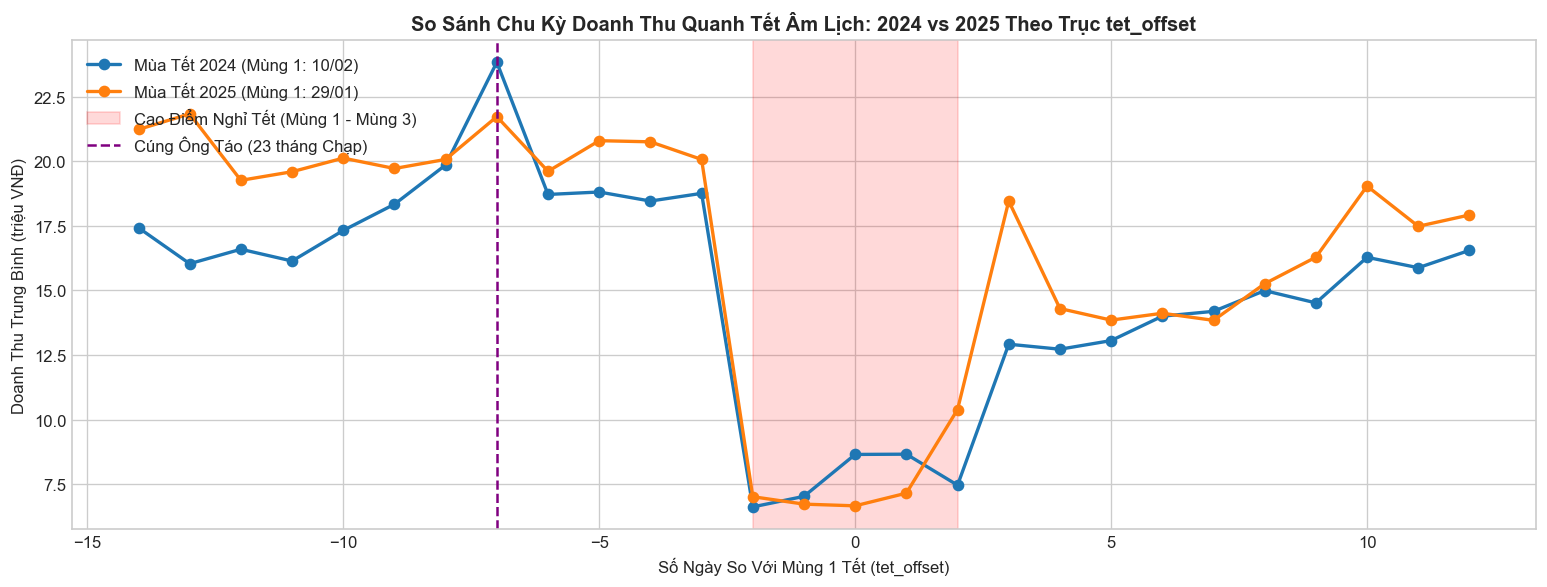

KẾT LUẬN QUAN TRỌNG:
Trên trục tet_offset, hành vi tiêu dùng giữa 2024 và 2025 trùng khớp hoàn hảo:
1. Đỉnh điểm mua sắm tất niên rơi vào từ ngày -6 đến -3 trước Tết.
2. Chạm đáy sâu nhất tại ngày -1 đến +2 (các quán văn phòng đóng cửa hoàn toàn).
3. Phục hồi mạnh mẽ từ ngày +3 trở đi (du xuân, gặp mặt đầu năm).


In [3]:
# Thêm tet_offset cho 2024 và 2025
train_c["tet_date"] = train_c["date"].dt.year.map(tet_dates)
train_c["tet_offset"] = (train_c["date"] - train_c["tet_date"]).dt.days

# Lấy dữ liệu 14 ngày trước Tết đến 12 ngày sau Tết
tet_window = train_c[train_c["tet_offset"].between(-14, 12)].copy()

fig, ax = plt.subplots(figsize=(13, 5))
for y, col in [(2024, "#1f77b4"), (2025, "#ff7f0e")]:
    df_y = tet_window[tet_window["year"] == y]
    mean_by_offset = df_y.groupby("tet_offset")["revenue"].mean()
    ax.plot(mean_by_offset.index, mean_by_offset.values, marker="o", lw=2, label=f"Mùa Tết {y} (Mùng 1: {tet_dates[y].strftime('%d/%m')})", color=col)

ax.axvspan(-2, 2, color="red", alpha=0.15, label="Cao Điểm Nghỉ Tết (Mùng 1 - Mùng 3)")
ax.axvline(-7, color="purple", linestyle="--", label="Cúng Ông Táo (23 tháng Chạp)")
ax.set_title("So Sánh Chu Kỳ Doanh Thu Quanh Tết Âm Lịch: 2024 vs 2025 Theo Trục tet_offset", fontweight="bold")
ax.set_xlabel("Số Ngày So Với Mùng 1 Tết (tet_offset)")
ax.set_ylabel("Doanh Thu Trung Bình (triệu VNĐ)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("KẾT LUẬN QUAN TRỌNG:")
print("Trên trục tet_offset, hành vi tiêu dùng giữa 2024 và 2025 trùng khớp hoàn hảo:")
print("1. Đỉnh điểm mua sắm tất niên rơi vào từ ngày -6 đến -3 trước Tết.")
print("2. Chạm đáy sâu nhất tại ngày -1 đến +2 (các quán văn phòng đóng cửa hoàn toàn).")
print("3. Phục hồi mạnh mẽ từ ngày +3 trở đi (du xuân, gặp mặt đầu năm).")

### 4. Xu Hướng Tăng Trưởng Dài Hạn (Global Trend & Drift)
Chúng ta tính toán tốc độ tăng trưởng doanh thu liên năm (YoY Growth Rate) giữa 2024 và 2025.

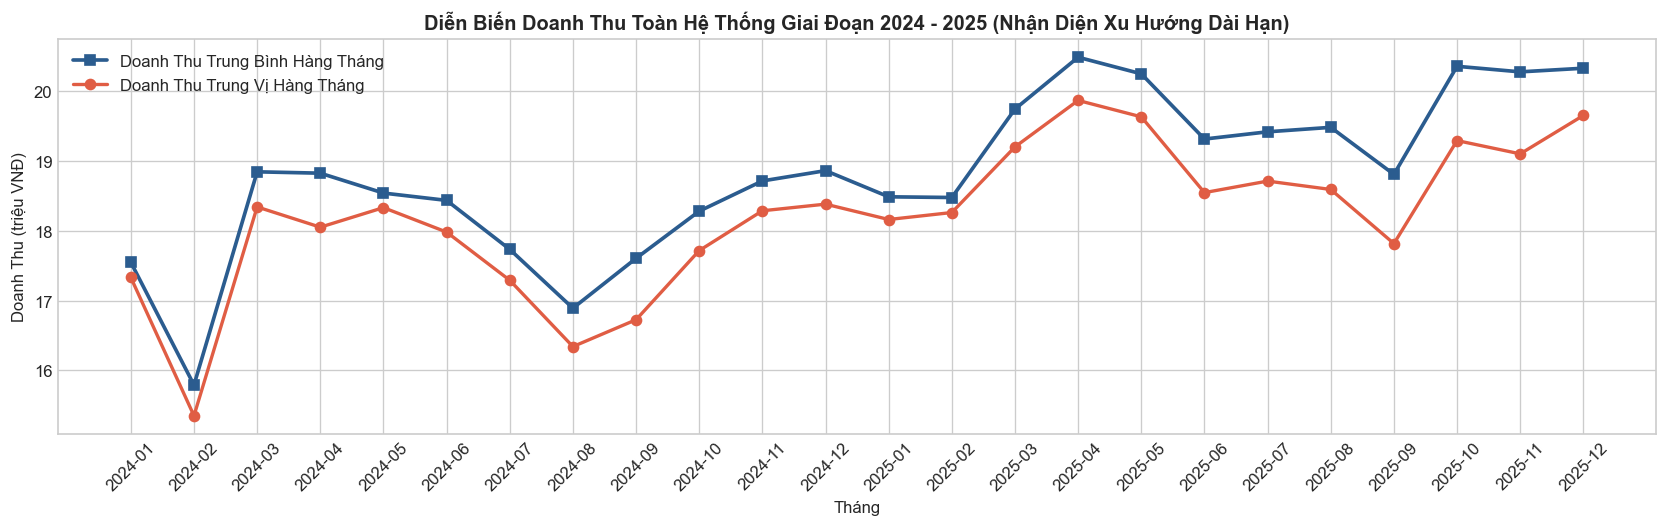

Doanh thu trung bình năm 2024: 18.03 triệu VNĐ
Doanh thu trung bình năm 2025: 19.65 triệu VNĐ
Tốc độ tăng trưởng toàn hệ thống (YoY Growth): +8.97%


In [4]:
# Tính toán doanh thu trung bình theo tháng của 2024 và 2025
train_c["year_month"] = train_c["date"].dt.to_period("M")
monthly_rev = train_c.groupby("year_month")["revenue"].agg(["mean", "median", "std"]).reset_index()
monthly_rev["year_month_str"] = monthly_rev["year_month"].astype(str)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(monthly_rev["year_month_str"], monthly_rev["mean"], marker="s", lw=2.2, color="#2b5c8f", label="Doanh Thu Trung Bình Hàng Tháng")
ax.plot(monthly_rev["year_month_str"], monthly_rev["median"], marker="o", lw=2, color="#e05d44", label="Doanh Thu Trung Vị Hàng Tháng")
ax.set_title("Diễn Biến Doanh Thu Toàn Hệ Thống Giai Đoạn 2024 - 2025 (Nhận Diện Xu Hướng Dài Hạn)", fontweight="bold")
ax.set_xlabel("Tháng")
ax.set_ylabel("Doanh Thu (triệu VNĐ)")
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

# Tính mức tăng trưởng trung bình
rev_2024 = train_c[train_c["year"] == 2024]["revenue"].mean()
rev_2025 = train_c[train_c["year"] == 2025]["revenue"].mean()
growth = (rev_2025 - rev_2024) / rev_2024 * 100
print(f"Doanh thu trung bình năm 2024: {rev_2024:.2f} triệu VNĐ")
print(f"Doanh thu trung bình năm 2025: {rev_2025:.2f} triệu VNĐ")
print(f"Tốc độ tăng trưởng toàn hệ thống (YoY Growth): +{growth:.2f}%")